In [25]:
import numpy as np
import matplotlib.pyplot as plt




In [26]:
kernels = [
    "accumulate_squared_opencv",
    "bilateral_filter_opencv",
    "accumulate_vitis",
    "auto_exposure_correction_opencv",
    "accumulate_weighted_opencv",
    "add_weighted_opencv",
    "sobel_filter_opencv",
    "reduce_avg_opencv",
]

models = [
    "Claude Sonnet 4.5",
    "Gemini 2.5 Pro",
    "Gemini 2.5 Flash",
    "Qwen3 Coder",
    "Vision Library",
]

# Replace the ... with the numbers from your table, use np.nan for N/A
latencies = np.array([
    [16398, 1044, 16404, 16394, 17291],  # accumulate_squared_opencv
    [np.nan, np.nan, np.nan, np.nan, 24849],  # bilateral_filter_opencv
    [16401, 523, 16401, 16395, 17034],       # accumulate_vitis
    [np.nan, np.nan, np.nan, np.nan, 18874],  # auto_exposure_correction_opencv
    [16415, 534, 2079, 16394, 16394],        # accumulate_weighted_opencv
    [np.nan, 1042, np.nan, np.nan, 17675],    # add_weighted_opencv
    [np.nan, np.nan, np.nan, np.nan, 18321],  # sobel_filter_opencv
    [np.nan, np.nan, np.nan, np.nan, 22328],  # reduce_avg_opencv
])


vision = latencies[:, 4]                   # baseline per kernel
speedup = vision[:, None] / latencies      # elementwise division
speedup[:, 4] = 1.0                        # baseline speedup = 1

In [27]:
print(latencies*3.3)

[[54113.4  3445.2 54133.2 54100.2 57060.3]
 [    nan     nan     nan     nan 82001.7]
 [54123.3  1725.9 54123.3 54103.5 56212.2]
 [    nan     nan     nan     nan 62284.2]
 [54169.5  1762.2  6860.7 54100.2 54100.2]
 [    nan  3438.6     nan     nan 58327.5]
 [    nan     nan     nan     nan 60459.3]
 [    nan     nan     nan     nan 73682.4]]


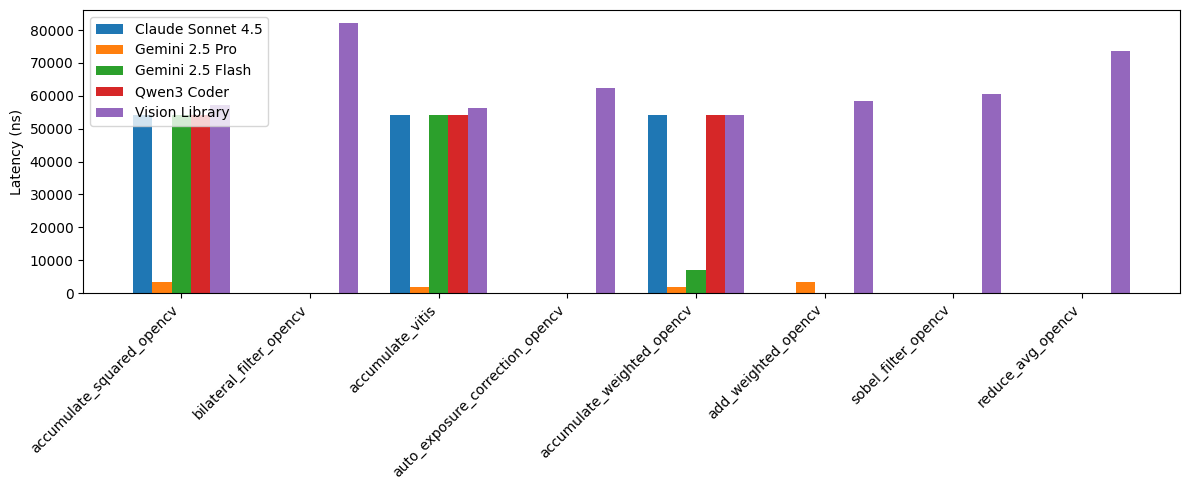

In [28]:
latencies_ns = latencies * 3.3
np.nan
x = np.arange(len(kernels))
width = 0.15

fig, ax = plt.subplots(figsize=(12, 5))

for i, model in enumerate(models):
    # offset each model’s bars
    ax.bar(
        x + (i - len(models)/2) * width + width/2,
        latencies_ns[:, i],
        width,
        label=model,
    )

ax.set_xticks(x)
ax.set_xticklabels(kernels, rotation=45, ha="right")
ax.set_ylabel("Latency (ns)")  # adjust units as needed
ax.legend()
fig.tight_layout()
plt.show()

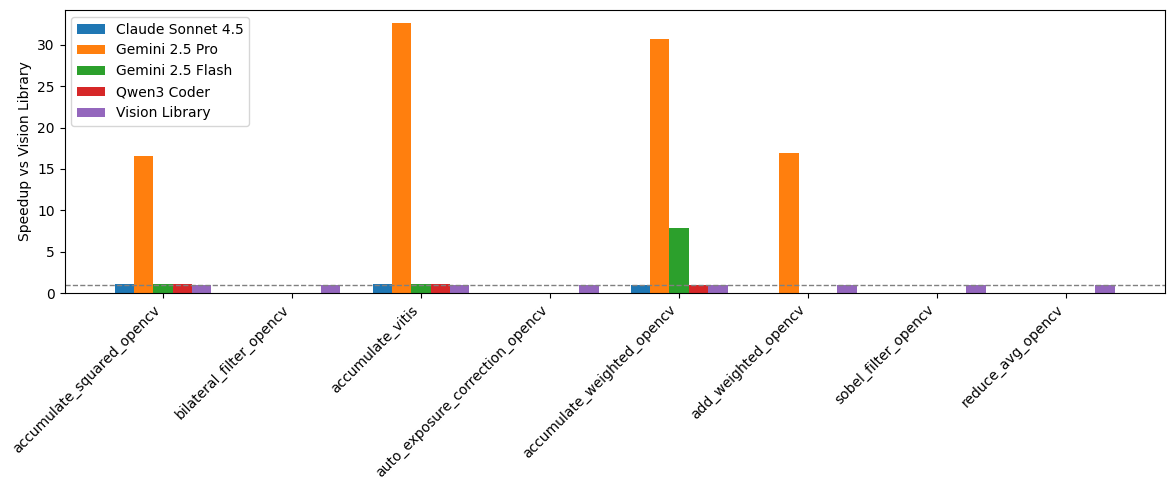

In [29]:
x = np.arange(len(kernels))
width = 0.15

fig, ax = plt.subplots(figsize=(12, 5))

for i, model in enumerate(models):
    ax.bar(
        x + (i - len(models)/2) * width + width/2,
        speedup[:, i],
        width,
        label=model,
    )

ax.set_xticks(x)
ax.set_xticklabels(kernels, rotation=45, ha="right")
ax.set_ylabel("Speedup vs Vision Library")
ax.axhline(1.0, color="gray", linewidth=1, linestyle="--")  # baseline
ax.legend()
fig.tight_layout()
plt.show()

In [30]:
## Accumulate
models = [
    "Claude Sonnet 4.5",
    "Gemini 2.5 Pro",
    "Gemini 2.5 Flash",
    "Qwen3 Coder",
    "Vision Library",
]

bram = [5, 30, 5, 4, 5]
dsp = [0, 0, 0, 0, 3]
ff = [2811, 2492, 2811, 1831, 7257]
lut = [2935, 2678, 2935, 1984, 9476]


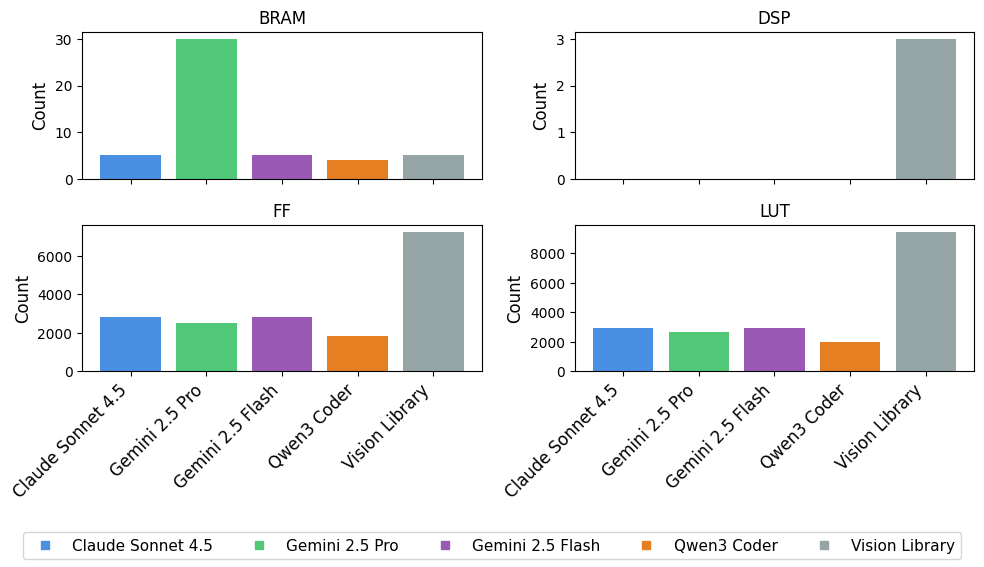

In [31]:
x = np.arange(len(models))

trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#95A5A6']

# same colors you used for models in previous charts
model_colors = {
    "Claude Sonnet 4.5": trial_colors[0],
    "Gemini 2.5 Pro":    trial_colors[1],
    "Gemini 2.5 Flash":  trial_colors[2],
    "Qwen3 Coder":       trial_colors[3],
    "Vision Library":    trial_colors[4],
}

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)

def plot_resource(ax, values, title):
    for i, (m, val) in enumerate(zip(models, values)):
        ax.bar(i, val, color=model_colors[m])
    ax.set_title(title)
    ax.set_ylabel("Count", fontsize = 12)

# BRAM
plot_resource(axes[0, 0], bram, "BRAM")

# DSP
plot_resource(axes[0, 1], dsp, "DSP")

# FF
plot_resource(axes[1, 0], ff, "FF")

# LUT
plot_resource(axes[1, 1], lut, "LUT")

# Shared x-axis labels on bottom row
for ax in axes[1, :]:
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha="right", fontsize=12)

# Single legend for models
handles = [
    plt.Line2D([0], [0], marker="s", linestyle="", color=c, label=m)
    for m, c in model_colors.items()
]
fig.legend(handles=handles, loc="lower center", ncol=len(models), fontsize=11)

fig.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.savefig("vitis_vision_resources.pdf")
plt.show()



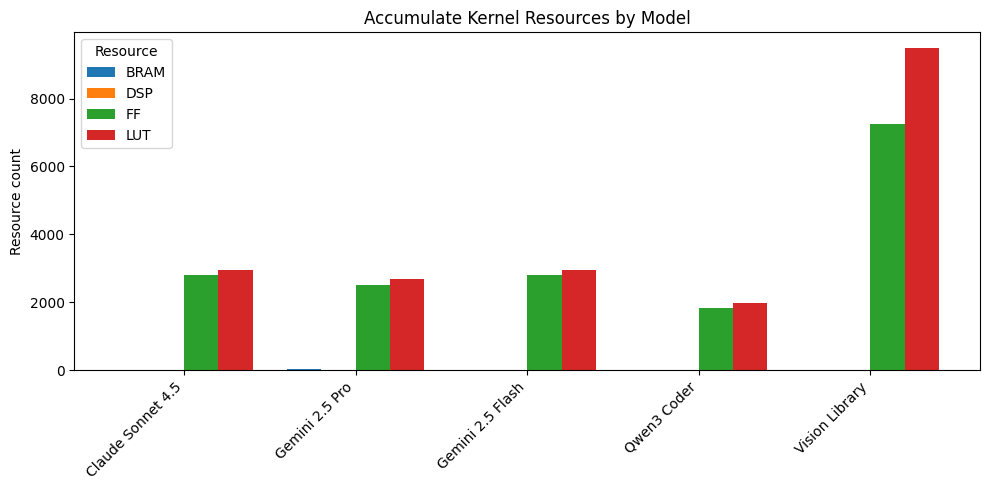

In [32]:
x = np.arange(len(models))           # model indices
width = 0.2                          # bar width

fig, ax = plt.subplots(figsize=(10, 5))

# offsets for each resource type within the cluster
ax.bar(x - 1.5*width, bram, width, label="BRAM")
ax.bar(x - 0.5*width, dsp,  width, label="DSP")
ax.bar(x + 0.5*width, ff,   width, label="FF")
ax.bar(x + 1.5*width, lut,  width, label="LUT")

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha="right")
ax.set_ylabel("Resource count")
ax.set_title("Accumulate Kernel Resources by Model")
ax.legend(title="Resource")

fig.tight_layout()
plt.show()
